# Phase 6 — Évaluation finale et optimisation business du seuil

**Objectif :** mesurer honnêtement la performance du modèle sur des clients jamais vus, puis transformer ses probabilités en **décision rentable** : qui contacter, et pour quel gain.

**Plan**
1. Évaluation finale sur le jeu de test
2. Choix de la règle de ciblage (seuil) et gain net de la campagne
3. Courbes de gain et de lift : cibler avec un budget limité
4. Sensibilité aux hypothèses économiques

**Règle d'or :** toutes les décisions (seuil compris) sont prises sur le **jeu d'entraînement**. Le jeu de test sert uniquement à **mesurer** le résultat de ces décisions.

**Hypothèses économiques** (cadrage, Phase 0) : action de rétention à 50 $, 30 % des partants contactés restent, valeur d'un client retenu = 12 mois de facture.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss
from sklearn.calibration import calibration_curve

from churn.config import RANDOM_STATE, DEFAULT_BUSINESS
from churn.data import load_clean
from churn.features import split_data
from churn.models import load_model
from churn.viz import set_style, save_fig, fmt_pct, fmt_int, BLUE, ORANGE, AQUA, TEXT, TEXT_SECONDARY, GRID

warnings.filterwarnings("ignore", category=UserWarning)
set_style()
dec = lambda v, d=3: f"{v:.{d}f}".replace(".", ",")      # virgule décimale
usd = lambda v: f"{fmt_int(v)} $"

X_train, X_test, y_train, y_test = split_data(load_clean())
model, card = load_model("churn_model")
proba_test = model.predict_proba(X_test)[:, 1]
print(f"Modèle : {card['model']} — entraîné le {card['created_at'][:10]} sur {fmt_int(card['n_train'])} clients")
print(f"Jeu de test : {fmt_int(len(X_test))} clients jamais vus, {fmt_pct(y_test.mean())} de churn")

Modèle : Régression logistique (optimisée) — entraîné le 2026-11-19 sur 5 634 clients
Jeu de test : 1 409 clients jamais vus, 26,5 % de churn


## 1. Évaluation finale sur le jeu de test

Un score sur 1 409 clients reste soumis au hasard de l'échantillon. On l'accompagne d'un **intervalle de confiance à 95 % par bootstrap** : on rééchantillonne le jeu de test 1 000 fois (tirage avec remise) et on regarde la dispersion des scores.

In [2]:
metrics = {"pr_auc": average_precision_score, "roc_auc": roc_auc_score, "brier": brier_score_loss}
y_arr = y_test.to_numpy()
rng = np.random.default_rng(RANDOM_STATE)
boot = []
for _ in range(1000):
    idx = rng.integers(0, len(y_arr), len(y_arr))
    boot.append({k: f(y_arr[idx], proba_test[idx]) for k, f in metrics.items()})
boot = pd.DataFrame(boot)

evaluation = pd.DataFrame({
    "validation croisée (train)": {k: card[f"cv_{k}"] for k in metrics},
    "test": {k: f(y_arr, proba_test) for k, f in metrics.items()},
    "IC 95 % bas": boot.quantile(0.025),
    "IC 95 % haut": boot.quantile(0.975),
})
evaluation.index = ["PR-AUC", "ROC-AUC", "Brier"]
evaluation.style.format("{:.4f}")

,validation croisée (train),test,IC 95 % bas,IC 95 % haut
PR-AUC,0.6746,0.6653,0.6151,0.7140
ROC-AUC,0.8511,0.8481,0.8264,0.8688
Brier,0.1326,0.1345,0.1236,0.1444


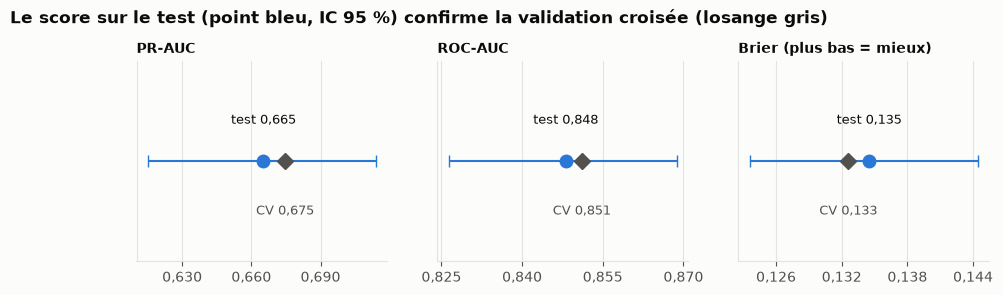

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(11, 2.6))
for ax, (name, row) in zip(axes, evaluation.iterrows()):
    ax.errorbar(row["test"], 0, xerr=[[row["test"] - row["IC 95 % bas"]], [row["IC 95 % haut"] - row["test"]]],
                fmt="o", markersize=9, color=BLUE, ecolor=BLUE, elinewidth=1.5, capsize=4)
    ax.plot(row["validation croisée (train)"], 0, marker="D", markersize=8, color=TEXT_SECONDARY, ls="none")
    ax.text(row["test"], 0.3, f"test {dec(row['test'])}", ha="center", fontsize=9, color=TEXT)
    ax.text(row["validation croisée (train)"], -0.35, f"CV {dec(row['validation croisée (train)'])}",
            ha="center", va="top", fontsize=9, color=TEXT_SECONDARY)
    ax.set_ylim(-0.8, 0.8)
    ax.set_yticks([])
    ax.grid(axis="y", visible=False)
    ax.xaxis.set_major_locator(plt.MaxNLocator(4))
    ax.xaxis.set_major_formatter(lambda v, _: dec(v, 3))
    ax.set_title(name + (" (plus bas = mieux)" if name == "Brier" else ""), fontsize=10)
fig.suptitle("Le score sur le test (point bleu, IC 95 %) confirme la validation croisée (losange gris)",
             x=0.01, ha="left", fontsize=12, fontweight="bold", color=TEXT, y=1.08)
save_fig(fig, "06_test_vs_cv.png")
plt.show()

**Lecture :** sur des clients jamais vus, le modèle obtient une **PR-AUC de 0,665** (IC 95 % : 0,615 – 0,714), une **ROC-AUC de 0,848** et un **Brier de 0,135**. Les scores de validation croisée tombent **à l'intérieur** des intervalles : la Phase 5 n'était pas optimiste, le modèle **généralise** comme prévu.

Pour situer : un classement au hasard donnerait une PR-AUC égale au taux de churn (0,265). Le modèle fait **2,5 fois mieux**.

### 1.1 Les probabilités sont-elles fiables sur le test ?

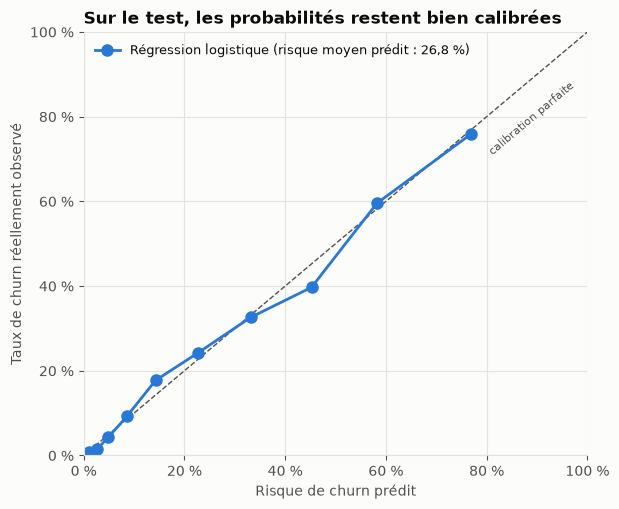

Taux de churn réel du test : 26,5 %


In [4]:
frac_pos, mean_pred = calibration_curve(y_test, proba_test, n_bins=10, strategy="quantile")
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.plot([0, 1], [0, 1], ls="--", lw=1, color=TEXT_SECONDARY)
ax.text(0.80, 0.71, "calibration parfaite", rotation=40, fontsize=8, color=TEXT_SECONDARY)
ax.plot(mean_pred, frac_pos, marker="o", markersize=8, lw=2, color=BLUE,
        label=f"Régression logistique (risque moyen prédit : {fmt_pct(proba_test.mean())})")
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="Risque de churn prédit", ylabel="Taux de churn réellement observé")
ax.xaxis.set_major_formatter(lambda v, _: fmt_pct(v, 0))
ax.yaxis.set_major_formatter(lambda v, _: fmt_pct(v, 0))
ax.legend(loc="upper left", fontsize=9)
ax.set_title("Sur le test, les probabilités restent bien calibrées")
save_fig(fig, "06_calibration_test.png")
plt.show()
print(f"Taux de churn réel du test : {fmt_pct(y_test.mean())}")

**Lecture :** la courbe suit la diagonale et le risque moyen prédit (26,8 %) colle au taux réel (26,5 %). C'est la condition pour la suite : on va **multiplier ces probabilités par des dollars**. Des probabilités biaisées donneraient des gains faux.